# RoadNet (Alqethami et al., 2022) — Balanced Adaptation to BDRoad-Sense

Paper settings preserved where practical:
- 256x256 input
- Conv 32 -> Conv 64, kernel 5x5, stride 1, padding 2
- ReLU + MaxPool
- FC1 = 13
- Batch size 32
- 20 epochs
- SGD, learning rate 0.0001, momentum 0.9
- Rotation 23°, horizontal flip 0.5, zoom and brightness augmentation

Fair-comparison adaptation:
- Final layer changed to 2 classes: Normal / Damaged
- Weighted Cross Entropy added to handle the imbalance in BDRoad-Sense

In [1]:
from pathlib import Path
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

SEED = 42
DATA_DIR = Path("road_dataset_224")

IMAGE_SIZE = 256
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 0.0001
MOMENTUM = 0.9
DROPOUT_P = 0.5

CLASS_TO_IDX = {"Normal": 0, "Damaged": 1}
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 5080


In [2]:
def remap_labels(dataset):
    dataset.samples = [
        (path, CLASS_TO_IDX[Path(path).parent.name])
        for path, _ in dataset.samples
    ]
    dataset.imgs = dataset.samples
    dataset.targets = [label for _, label in dataset.samples]
    dataset.classes = ["Normal", "Damaged"]
    dataset.class_to_idx = CLASS_TO_IDX.copy()
    return dataset

def load_split(split, transform):
    ds = datasets.ImageFolder(DATA_DIR / split, transform=transform)
    return remap_labels(ds)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(23),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=0, scale=(0.5, 1.5)),
    transforms.ColorJitter(brightness=(0.5, 1.5)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_ds = load_split("train", train_transform)
val_ds = load_split("val", eval_transform)
test_ds = load_split("test", eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

for name, ds in [("Train", train_ds), ("Validation", val_ds), ("Test", test_ds)]:
    counts = np.bincount(ds.targets, minlength=2)
    print(f"{name}: Normal={counts[0]}, Damaged={counts[1]}, Total={len(ds)}")

Train: Normal=928, Damaged=2470, Total=3398
Validation: Normal=198, Damaged=529, Total=727
Test: Normal=200, Damaged=531, Total=731


In [3]:
class RoadNet(nn.Module):
    def __init__(self, num_classes=2, dropout_p=0.5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=5, stride=1, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(dropout_p),

            nn.Conv2d(32, 64, kernel_size=5, stride=1, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(dropout_p),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 64 * 64, 13),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_p),
            nn.Linear(13, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = RoadNet(num_classes=2, dropout_p=DROPOUT_P).to(device)

train_counts = np.bincount(train_ds.targets, minlength=2)
class_weights = len(train_ds) / (2.0 * train_counts)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=device)

print("Class counts:", train_counts)
print("Class weights:", class_weights)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE,
    momentum=MOMENTUM
)

Class counts: [ 928 2470]
Class weights: tensor([1.8308, 0.6879], device='cuda:0')


In [4]:
best_val_loss = float("inf")
best_path = "roadnet_saudi_balanced_best.pth"
history = []

if device.type == "cuda":
    torch.cuda.synchronize()
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)
            val_loss += loss.item()

    val_loss /= len(val_loader)

    history.append({
        "Epoch": epoch,
        "Train Loss": train_loss,
        "Validation Loss": val_loss
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_path)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

if device.type == "cuda":
    torch.cuda.synchronize()

elapsed = time.time() - start_time
print(f"Training time: {int(elapsed//60)} min {int(elapsed%60)} sec")

Epoch 01/20 | Train Loss: 0.7074 | Val Loss: 0.6336
Epoch 02/20 | Train Loss: 0.6988 | Val Loss: 0.6380
Epoch 03/20 | Train Loss: 0.6950 | Val Loss: 0.6280
Epoch 04/20 | Train Loss: 0.6948 | Val Loss: 0.6289
Epoch 05/20 | Train Loss: 0.6934 | Val Loss: 0.6283
Epoch 06/20 | Train Loss: 0.6897 | Val Loss: 0.6349
Epoch 07/20 | Train Loss: 0.6853 | Val Loss: 0.6273
Epoch 08/20 | Train Loss: 0.6828 | Val Loss: 0.6186
Epoch 09/20 | Train Loss: 0.6838 | Val Loss: 0.6225
Epoch 10/20 | Train Loss: 0.6796 | Val Loss: 0.6249
Epoch 11/20 | Train Loss: 0.6744 | Val Loss: 0.6199
Epoch 12/20 | Train Loss: 0.6749 | Val Loss: 0.6227
Epoch 13/20 | Train Loss: 0.6757 | Val Loss: 0.6235
Epoch 14/20 | Train Loss: 0.6758 | Val Loss: 0.6171
Epoch 15/20 | Train Loss: 0.6681 | Val Loss: 0.6052
Epoch 16/20 | Train Loss: 0.6677 | Val Loss: 0.6106
Epoch 17/20 | Train Loss: 0.6765 | Val Loss: 0.6144
Epoch 18/20 | Train Loss: 0.6732 | Val Loss: 0.6110
Epoch 19/20 | Train Loss: 0.6703 | Val Loss: 0.6280
Epoch 20/20 


Final Test Results
Accuracy: 0.7565
Precision: 0.8812
Recall: 0.7684
F1: 0.8209

Classification Report:
              precision    recall  f1-score   support

      Normal       0.54      0.72      0.62       200
     Damaged       0.88      0.77      0.82       531

    accuracy                           0.76       731
   macro avg       0.71      0.75      0.72       731
weighted avg       0.79      0.76      0.77       731



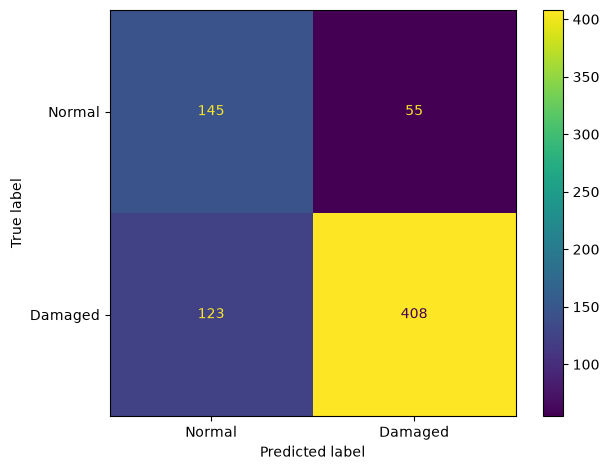

In [5]:
model.load_state_dict(torch.load(best_path, map_location=device))
model.eval()

y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()

        y_pred.extend(preds)
        y_true.extend(labels.numpy())

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
recall = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
f1 = f1_score(y_true, y_pred, pos_label=1, zero_division=0)

print("\nFinal Test Results")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1: {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    target_names=["Normal", "Damaged"],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(
    cm,
    display_labels=["Normal", "Damaged"]
).plot(values_format="d")
plt.tight_layout()
plt.show()

In [6]:
def robustness_transform(brightness=1.0, blur=None):
    steps = [transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))]

    if brightness != 1.0:
        steps.append(
            transforms.Lambda(
                lambda img, f=brightness: TF.adjust_brightness(img, f)
            )
        )

    if blur is not None:
        k, sigma = blur
        steps.append(transforms.GaussianBlur(kernel_size=k, sigma=sigma))

    steps += [
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ]
    return transforms.Compose(steps)

conditions = {
    "Clean": (1.0, None),
    "Low Brightness (0.7)": (0.7, None),
    "High Brightness (1.3)": (1.3, None),
    "Mild Blur (k=5, sigma=1.0)": (1.0, (5, 1.0)),
    "Strong Blur (k=9, sigma=2.0)": (1.0, (9, 2.0)),
}

rows = []

for condition, (brightness, blur) in conditions.items():
    ds = load_split(
        "test",
        robustness_transform(brightness=brightness, blur=blur)
    )
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

    yt, yp = [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            preds = model(images).argmax(dim=1).cpu().numpy()
            yp.extend(preds)
            yt.extend(labels.numpy())

    rows.append({
        "Condition": condition,
        "Accuracy": accuracy_score(yt, yp),
        "Precision": precision_score(yt, yp, pos_label=1, zero_division=0),
        "Recall": recall_score(yt, yp, pos_label=1, zero_division=0),
        "F1": f1_score(yt, yp, pos_label=1, zero_division=0),
    })

robustness_df = pd.DataFrame(rows)

print(
    robustness_df.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.4f}".format,
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1": "{:.4f}".format,
        }
    )
)

robustness_df.to_csv("roadnet_saudi_balanced_robustness.csv", index=False)

                   Condition Accuracy Precision Recall     F1
                       Clean   0.7565    0.8812 0.7684 0.8209
        Low Brightness (0.7)   0.7073    0.7496 0.8964 0.8165
       High Brightness (1.3)   0.7401    0.8152 0.8305 0.8228
  Mild Blur (k=5, sigma=1.0)   0.7524    0.8855 0.7571 0.8162
Strong Blur (k=9, sigma=2.0)   0.7332    0.8784 0.7345 0.8000
